# Упражнение 2.2: выделение подматрицы изображения

Задача: считать изображение через OpenCV, преобразовать его из `BGR` в `RGB`, выделить подматрицу строк `1393..2242` и столбцов `2420..3099` включительно, затем определить идентификатор совпадающего изображения.

## 1. Импорты и файлы

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SOURCE_PATH = Path('input_images/andrew-small-EfhCUc_fjrU-unsplash.jpg')
CANDIDATE_DIR = Path('candidate_crops')
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

if not SOURCE_PATH.exists():
    raise FileNotFoundError(f'Не найден исходный файл: {SOURCE_PATH}')
if not CANDIDATE_DIR.exists():
    raise FileNotFoundError(f'Не найдена папка с вариантами: {CANDIDATE_DIR}')

## 2. Чтение изображения и перевод в RGB

OpenCV читает цветные изображения в порядке каналов `BGR`, поэтому для обычного отображения и сравнения переводим в `RGB`.

In [2]:
image_bgr = cv2.imread(str(SOURCE_PATH), cv2.IMREAD_COLOR)
if image_bgr is None:
    raise ValueError('OpenCV не смог считать изображение')

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width, channels = image_rgb.shape

print(f'Ширина: {width} px')
print(f'Высота: {height} px')
print(f'Каналы: {channels}')

Ширина: 5261 px
Высота: 3507 px
Каналы: 3


## 3. Выделение подматрицы

Так как границы в задании включительные, в срезах Python нужно использовать `end + 1`.

Размер фрагмента: 680x850 px


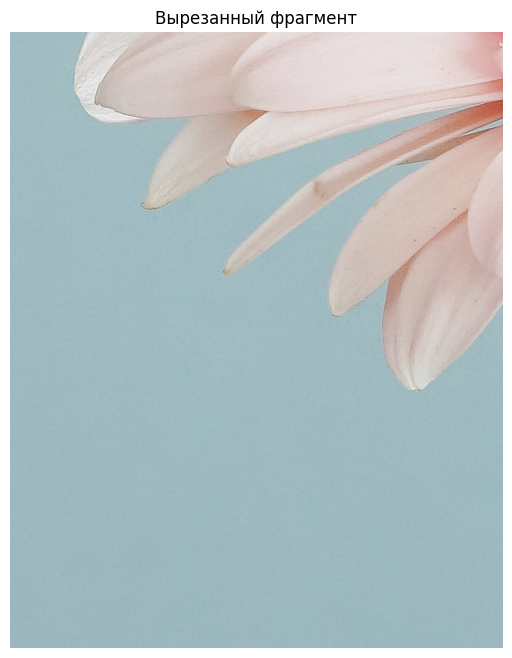

In [3]:
row_start, row_end = 1393, 2242
col_start, col_end = 2420, 3099

crop = image_rgb[row_start:row_end + 1, col_start:col_end + 1]
print(f'Размер фрагмента: {crop.shape[1]}x{crop.shape[0]} px')

Image.fromarray(crop).save(OUTPUT_DIR / 'task2_2_crop.png')

plt.figure(figsize=(7, 8))
plt.imshow(crop)
plt.title('Вырезанный фрагмент')
plt.axis('off')
plt.show()

## 4. Сравнение с предложенными вариантами

Сравниваем наш фрагмент с кандидатами по средней абсолютной ошибке. Для правильного JPEG-варианта ошибка близка к нулю, потому что отличается только сжатие.

In [4]:
rows = []
for path in sorted(CANDIDATE_DIR.glob('crop_*_andrew*.jpg')):
    candidate_id = path.name.split('_')[1]
    candidate = np.array(Image.open(path).convert('RGB'))

    same_shape = candidate.shape == crop.shape
    if same_shape:
        candidate_for_compare = candidate
    else:
        candidate_for_compare = np.array(
            Image.fromarray(candidate).resize((crop.shape[1], crop.shape[0]))
        )

    diff = crop.astype(np.int16) - candidate_for_compare.astype(np.int16)
    mae = float(np.mean(np.abs(diff)))
    mse = float(np.mean(diff.astype(np.float32) ** 2))

    rows.append({
        'id': candidate_id,
        'same_shape': same_shape,
        'candidate_size': f'{candidate.shape[1]}x{candidate.shape[0]}',
        'mae': mae,
        'mse': mse,
    })

comparison = pd.DataFrame(rows).sort_values(['mae', 'mse']).reset_index(drop=True)
display(comparison)

answer = comparison.loc[0, 'id']
print(f'Ответ: {answer}')

,id,same_shape,candidate_size,mae,mse
0,566,True,680x850,0.757674,9.431875
1,837,False,830x700,7.629671,247.894150
2,437,False,730x990,7.781370,265.269806
3,987,False,540x480,8.049639,257.386047
4,292,False,510x690,8.111287,265.817078
5,753,False,730x720,8.240238,275.667969
6,974,False,980x440,8.518096,296.238007
7,127,False,710x650,8.717009,322.649139
8,765,False,940x650,9.540536,335.509186
9,751,False,560x650,10.638400,375.239441


Ответ: 566


## Ответ для формы

Идентификатор изображения: `566`